In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.max_columns", 20)

sns.set_theme(style="whitegrid", context="notebook")

In [2]:
data_dir = Path("data/raw")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT", "PROPERTIES"]
files = {"body": data_dir / "soc-redditHyperlinks-body.tsv",
         "title": data_dir / "soc-redditHyperlinks-title.tsv"}
for path in files.values():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. See dataset_information.md for download instructions.")

parts = []
for location, path in files.items():
    part = pd.read_csv(path, sep="	", usecols=columns,
                       dtype={"SOURCE_SUBREDDIT": "string", "TARGET_SUBREDDIT": "string",
                              "POST_ID": "string", "TIMESTAMP": "string", "LINK_SENTIMENT": "int8"})
    part["LOCATION"] = location
    parts.append(part)
links = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(links):,} links: {len(parts[0]):,} body and {len(parts[1]):,} title")

Loaded 858,488 links: 286,561 body and 571,927 title


In [3]:
links.head(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES,LOCATION
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08...",body
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049...",body
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082...",body
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0....",body
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0....",body
5,dogemarket,dogecoin,1u4w7bs,2013-12-31 18:35:44,1,"1328.0,1110.0,0.768825301205,0.0143072289157,0...",body
6,locationbot,legaladvice,1u4wfes,2014-01-07 20:17:41,1,"184.0,172.0,0.744565217391,0.0326086956522,0.0...",body
7,indiefied,aww,1u50pos,2014-03-03 17:00:35,1,"295.0,256.0,0.749152542373,0.0203389830508,0.0...",body
8,posthardcore,bestof2013,1u5ccus,2013-12-31 23:16:20,1,"3927.0,3488.0,0.719887955182,0.0229182582124,0...",body
9,posthardcore,corejerk,1u5ccus,2013-12-31 23:16:20,1,"3927.0,3488.0,0.719887955182,0.0229182582124,0...",body


In [4]:
links["VADER_POS"] = pd.to_numeric(
    links["PROPERTIES"].str.split(",").str[19],
    errors="coerce"
)

links["VADER_NEG"] = pd.to_numeric(
    links["PROPERTIES"].str.split(",").str[20],
    errors="coerce"
)

In [5]:
links.head(5)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES,LOCATION,VADER_POS,VADER_NEG
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08...",body,0.080,0.1748
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049...",body,0.000,0.5538
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082...",body,0.000,0.0000
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0....",body,0.026,0.9672
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0....",body,0.039,0.8906


In [6]:
Positive_grouped = (
    links[links["LINK_SENTIMENT"] == 1]
    .groupby("LOCATION")["PROPERTIES"]
    .apply(lambda s: s.str[19])
)

Negative_grouped = (
    links[links["LINK_SENTIMENT"] == -1]
    .groupby("LOCATION")["PROPERTIES"]
    .apply(lambda s: s.str[20])
)
print(Negative_grouped.index.unique())
print(Negative_grouped.index)

MultiIndex([( 'body',      1),
            ( 'body',     34),
            ( 'body',     43),
            ( 'body',     53),
            ( 'body',     55),
            ( 'body',     68),
            ( 'body',     99),
            ( 'body',    107),
            ( 'body',    120),
            ( 'body',    132),
            ...
            ('title', 858434),
            ('title', 858452),
            ('title', 858457),
            ('title', 858467),
            ('title', 858469),
            ('title', 858473),
            ('title', 858478),
            ('title', 858480),
            ('title', 858483),
            ('title', 858486)],
           names=['LOCATION', None], length=82210)
MultiIndex([( 'body',      1),
            ( 'body',     34),
            ( 'body',     43),
            ( 'body',     53),
            ( 'body',     55),
            ( 'body',     68),
            ( 'body',     99),
            ( 'body',    107),
            ( 'body',    120),
            ( 'body',    132),
  

In [7]:
vader_body_neg = Negative_grouped.loc["body"]
vader_title_neg = Negative_grouped.loc["title"]




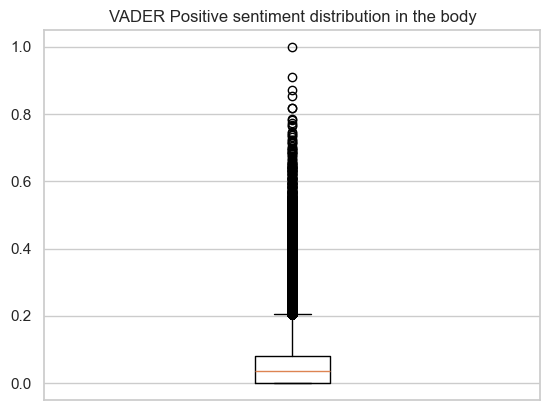

In [8]:

plt.boxplot(links.loc[links["LOCATION"] == "body", "VADER_POS"])
plt.xticks([])
plt.title("VADER Positive sentiment distribution in the body")
plt.show()

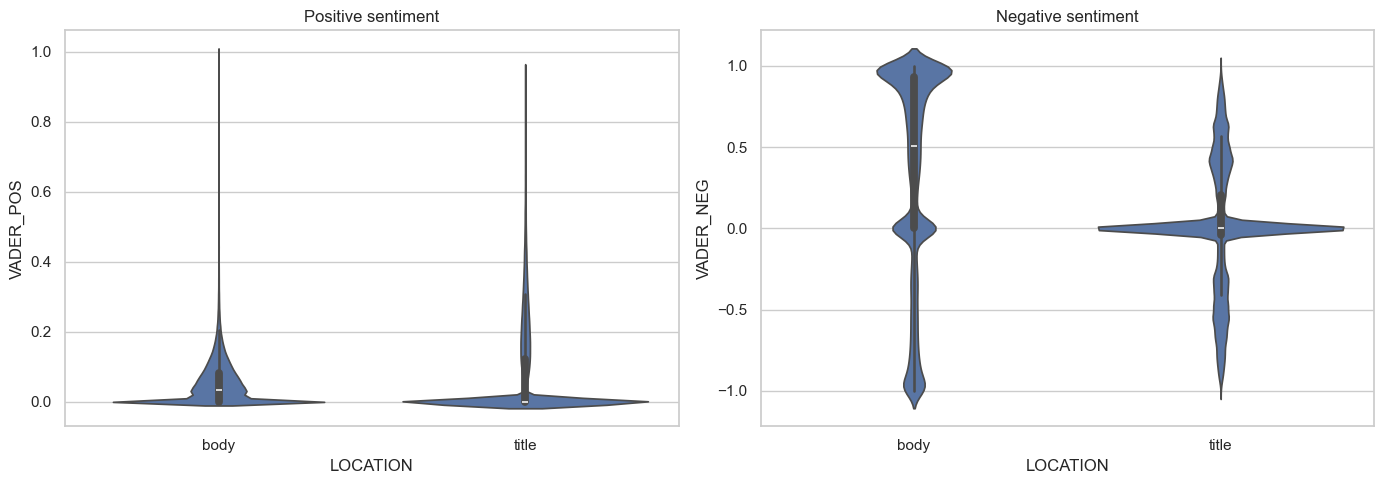

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(
    x="LOCATION",
    y="VADER_POS",
    data=links,
    ax=axes[0]
)
axes[0].set_title("Positive sentiment")

sns.violinplot(
    x="LOCATION",
    y="VADER_NEG",
    data=links,
    ax=axes[1]
)
axes[1].set_title("Negative sentiment")

plt.tight_layout()
plt.show()